# Esperimento — Predictive Regulated Search sulla dama

In questo notebook una ricerca alfa-beta sceglie la mossa in posizioni di dama, e
mettiamo a confronto tre modi di farla: A, la ricerca classica con il materiale alle
foglie; B, la stessa ricerca con un predittore appreso alle foglie; C, la ricerca di B
più un regolatore che decide su quali mosse spendere il calcolo. Le scelte vengono
giudicate dal **maestro**, una ricerca molto più profonda (7 semimosse) calcolata
offline da `make_data.py`: nessun sistema la vede, serve solo a dare i voti.

Il percorso segue la consegna: prima la ricerca, poi il predittore e il modo in cui la
ricerca lo usa, poi il regolatore e le probabilità su cui lavora, gli errori del
predittore, il confronto fra A, B e C e i casi in cui conviene cercare anche una mossa
che sembra brutta. In fondo ci sono le varianti del tipo "che cosa succede se…".
Il report con le spiegazioni complete è `DOCUMENTAZIONE.docx`.

I dati e il modello sono già in `data/` (si rigenerano con `python make_data.py` e
`python predictor.py`). Le celle vanno eseguite in ordine, dall'inizio (*Run All*):
in tutto da un'ora a un'ora e mezza.

## Impostazione

Tutti i parametri dell'esperimento sono qui: per provare una variante basta cambiare
un valore e rieseguire tutto. Poi carichiamo il predittore e le posizioni di test,
ognuna con il valore che il maestro dà a ogni mossa.

In [1]:
import copy
import json
from statistics import mean

import joblib
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import softmax

from dama import Color, Dama
from search import minimaxA, minimaxB, minimaxC

DEPTH = 5          # profondita' della ricerca di A, B e C (semimosse)
RHO_MAX = 0.05     # probabilita' che il regolatore puo' lasciare alle mosse escluse
DELTA = 1.0        # soglia di instabilita' |r| (pedine)
NOISE = 0.1        # rumore sui pesi della rete nella variante "predittore meno accurato"
N_VARIANTS = 150   # le varianti del "che cosa succede se" girano sulle prime N posizioni, per fare prima

SYSTEMS = ["A  baseline", "B  predittiva", "C  con i nodi di B", "C  con i nodi di A"]

In [2]:
def load_positions(path="data/test.json"):
    """Le posizioni di test, ognuna con il valore di ogni mossa secondo il maestro."""
    with open(path) as f:
        data = json.load(f)
    positions = []
    for item in data:
        board = Dama.from_fen(item["fen"])
        ref = [item["values"][str(m)] for m in board.legal_moves]
        if max(ref) > min(ref):   # solo posizioni in cui la scelta conta
            positions.append((board, ref))
    return positions


model = joblib.load("data/model.joblib")
T = model.T        # temperatura di pi, calibrata da predictor.py
positions = load_positions()
print(f"{len(positions)} posizioni di test, temperatura calibrata T = {T:.1f}")

500 posizioni di test, temperatura calibrata T = 0.4


## La ricerca

Si cerca la mossa migliore per chi deve muovere. Uno **stato** è una posizione (dove
sono pedine e dame e a chi tocca), le alternative sono le mosse legali alla radice ed
**espandere** vuol dire eseguire una mossa: ogni mossa eseguita durante la ricerca conta
come un nodo, e i nodi sono la nostra misura del calcolo.

L'**orizzonte** è il punto in cui la ricerca esplicita si ferma e la posizione viene
valutata da una funzione: `DEPTH` semimosse per ogni mossa in A e B. La **frontiera
attiva** è la parte dell'orizzonte che può ancora ricevere calcolo. In A e B coincide con
tutte le mosse, perché le cercano tutte; in C è più stretta, e la decide il regolatore.
Una mossa che esce dalla frontiera non viene scartata: tiene la sua predizione,
partecipa alla scelta finale e può rientrare se le altre deludono.

## Il predittore

Il predittore è una piccola rete neurale (`predictor.py`) che guarda la posizione così
com'è, 128 bit, e stima il valore che le darebbe il maestro. I target vengono dal maestro
stesso, calcolato offline su 1500 posizioni di training: il suo costo non entra nel
budget del confronto.

Prima di usarlo nella ricerca vediamo quanto è accurato da solo, **senza nessuna
ricerca**: per ogni mossa confrontiamo il valore predetto con quello del maestro, e
accanto mettiamo il materiale che usa A.

- *errore medio*: di quante pedine si sbaglia il valore di una mossa;
- *mossa migliore indovinata*: quante volte la mossa con il valore più alto è anche
  una delle migliori per il maestro.

In [3]:
def accuracy(positions, values_of):
    """Errore medio sui valori delle mosse e frazione di mosse migliori indovinate."""
    errors, hits = [], []
    for board, ref in positions:
        pred = values_of(board)
        errors += [abs(p - r) for p, r in zip(pred, ref)]
        hits.append(ref[pred.index(max(pred))] == max(ref))
    return mean(errors), mean(hits)


for name, values_of in [("materiale (sistema A)", lambda b: minimaxA(b, 1)[1]),
                        ("predittore (B e C)", lambda b: minimaxB(b, 1, model)[1])]:
    error, hit = accuracy(positions, values_of)
    print(f"{name:<22} errore medio {error:.2f} pedine,  mossa migliore indovinata {hit:.0%}")

materiale (sistema A)  errore medio 1.12 pedine,  mossa migliore indovinata 56%


predittore (B e C)     errore medio 1.05 pedine,  mossa migliore indovinata 72%


Due controlli sulla scelta del modello. Se la rete fosse molto migliore sulle posizioni
di training che su quelle di test avrebbe imparato a memoria, quindi ripetiamo la misura
sul training. E per capire se serve davvero una rete, alleniamo una regressione lineare
sugli stessi esempi e la misuriamo sullo stesso test.

In [4]:
from sklearn.linear_model import LinearRegression

from predictor import from_json

error, hit = accuracy(load_positions("data/train.json"), lambda b: minimaxB(b, 1, model)[1])
print(f"{'rete, sul training':<22} errore medio {error:.2f} pedine,  mossa migliore indovinata {hit:.0%}")

_, X, y = from_json("data/train.json")
linear = LinearRegression().fit(X, y)
error, hit = accuracy(positions, lambda b: minimaxB(b, 1, linear)[1])
print(f"{'lineare, sul test':<22} errore medio {error:.2f} pedine,  mossa migliore indovinata {hit:.0%}")
print(f"\n{len(X)} esempi di training")

rete, sul training     errore medio 0.97 pedine,  mossa migliore indovinata 75%


lineare, sul test      errore medio 1.08 pedine,  mossa migliore indovinata 66%

10470 esempi di training


## La ricerca predittiva

B usa la predizione alle foglie: dove A conterebbe i pezzi, B chiede alla rete quanto
vale la posizione, come se la ricerca continuasse virtualmente più a fondo. Per il resto
B è identica ad A: cerca tutte le mosse alla stessa profondità.

Su una posizione di esempio, per ogni mossa: il valore che A e B darebbero fermandosi
alla prima semimossa (il materiale e la predizione), il valore dopo la ricerca a `DEPTH`
semimosse e il valore del maestro.

In [5]:
EXAMPLE = 1   # la posizione di test usata come esempio

board, ref = positions[EXAMPLE]
material1 = minimaxA(board, 1)[1]          # A fermo alla prima semimossa: il solo materiale
predicted = minimaxB(board, 1, model)[1]   # B fermo alla prima semimossa: la sola predizione
_, a_values, a_nodes = minimaxA(board, DEPTH)
_, b_values, b_nodes = minimaxB(board, DEPTH, model)

side = "bianco" if board.turn == Color.WHITE else "nero"
print(board)
print(f"\nmuove il {side}; A usa {a_nodes} nodi, B {b_nodes}\n")
print(f"{'mossa':<8} {'materiale':>9} {'predizione':>10} {'A a ' + str(DEPTH):>7} {'B a ' + str(DEPTH):>7} {'maestro':>8}")
for i, move in enumerate(board.legal_moves):
    print(f"{str(move):<8} {material1[i] + 0.0:>9.2f} {predicted[i]:>10.2f} {a_values[i] + 0.0:>7.2f} {b_values[i]:>7.2f} {ref[i] + 0.0:>8}")

. . . b . . . .     .  1 .  2 .  3 .  4
 w . . . b . . .      5 .  6 .  7 .  8 .
 . . . . . . . W     .  9 . 10 . 11 . 12
 b . . . w . . .     13 . 14 . 15 . 16 .
 . . . . . b . b     . 17 . 18 . 19 . 20
 w . b . . . . .     21 . 22 . 23 . 24 .
 . . . w . w . .     . 25 . 26 . 27 . 28
 B . . . w . . .     29 . 30 . 31 . 32 .

muove il nero; A usa 9735 nodi, B 15428

mossa    materiale predizione   A a 5   B a 5  maestro
2-6           0.00      -1.03   -1.00   -1.48     -1.0
7-10          0.00      -1.94   -1.00   -1.77     -1.0
19-23         0.00      -1.29   -1.00   -1.50     -1.0
20-24         0.00      -1.56   -1.00   -1.72     -1.0
22-25         0.00      -0.80    0.00   -0.66      0.0
7-11          0.00      -1.68   -1.00   -2.08     -1.0
13-17         0.00      -1.98   -1.00   -1.50     -1.0
19-24         0.00      -1.35   -1.00   -1.56     -1.0
29-25         0.00      -1.50   -1.00   -1.52     -1.0


## Il regolatore

B decide che cosa sembra promettente, ma spende lo stesso calcolo su ogni mossa. Il
regolatore di C decide invece *quanto* calcolo dare a ciascuna, guardando la ricerca
mentre procede.

C parte dalla predizione di ogni mossa. Questi valori attuali sono ciò che il regolatore
osserva (O_t): li trasforma in probabilità con π = softmax(V/T) e tiene nella frontiera
le mosse più probabili, finché insieme coprono 1 − `RHO_MAX` della probabilità. La
probabilità che resta sulle mosse escluse è ρ, la massa non risolta: quanto C
scommette che la mossa migliore non sia tra quelle che cerca. La decisione (U_t) è
quale mossa cercare adesso, la più probabile tra quelle della frontiera non ancora
cercate, oppure fermarsi, quando la frontiera è tutta cercata o i nodi sono finiti.
Dopo ogni ricerca il valore trovato prende il posto della predizione e il regolatore
ricalcola tutto. In questo modo il regolatore osserva la ricerca mentre procede: se una
mossa cercata delude, la sua probabilità passa alle altre, che possono entrare nella
frontiera; se si conferma, le altre perdono probabilità e se ne cercano meno.

π va letta sulle mosse migliori prese insieme: la somma di π sulle mosse che il maestro
considera migliori è la probabilità di prendere una mossa migliore scegliendo secondo π,
ed è la quantità che `predictor.py` massimizza quando sceglie la temperatura T. Mossa per
mossa non è una probabilità di essere la migliore, perché spesso più mosse hanno lo
stesso valore per il maestro.

## Quando la predizione sbaglia

Una predizione può sbagliare, e il suo errore può essere un'informazione utile. Lo
misuriamo confrontandola con una ricerca un po' più profonda: una mossa è **instabile**
se |r| = |V₃ − V₁| ≥ `DELTA`, con V₁ la predizione e V₃ il valore a 3 semimosse. Se le
mosse instabili sono quelle con l'errore più grande, |r| distingue le mosse che
"sembrano buone" da quelle che "hanno bisogno di essere pensate", cioè i casi in cui
fermarsi alla predizione è pericoloso.

In [6]:
stable, unstable = [], []   # per ogni mossa: (errore della predizione, errore a 3 semimosse)
hidden = []                 # mosse "brutte ma buone": per ognuna, se e' instabile
for board, ref in positions:
    v1 = minimaxB(board, 1, model)[1]
    v3 = minimaxB(board, 3, model)[1]
    for i in range(len(ref)):
        is_unstable = abs(v3[i] - v1[i]) >= DELTA
        (unstable if is_unstable else stable).append((abs(ref[i] - v1[i]), abs(ref[i] - v3[i])))
        if ref[i] == max(ref) and v1[i] <= max(v1) - DELTA:
            hidden.append(is_unstable)

print(f"Soglia |r| >= {DELTA}                errore fermandosi    errore fermandosi")
print(f"                                 alla predizione      a 3 semimosse")
for label, group in [("mosse stabili", stable), ("mosse instabili", unstable)]:
    print(f"{label:<16} n = {len(group):5d}   {mean(e[0] for e in group):10.2f}"
          f"           {mean(e[1] for e in group):10.2f}")

Soglia |r| >= 1.0                errore fermandosi    errore fermandosi
                                 alla predizione      a 3 semimosse
mosse stabili    n =  2824         0.81                 0.71
mosse instabili  n =   863         1.82                 0.89


## Il confronto fra A, B e C

In ognuna delle posizioni di test ogni sistema sceglie una mossa, che confrontiamo con
quella del maestro. A e B cercano tutte le mosse e contano i nodi. C gioca due volte,
con il limite di nodi che B e A hanno usato in quella posizione. Il limite è un tetto,
non una quantità da spendere: C si ferma appena ha cercato tutta la frontiera, quindi usa
al massimo i nodi del sistema con cui lo confrontiamo, e di solito meno.

- *mossa giusta*: la mossa scelta è una delle migliori per il maestro;
- *regret*: quante pedine si perdono rispetto alla mossa migliore (0 = mossa giusta);
- *nodi*: posizioni visitate, in media;
- *rho finale*: probabilità rimasta alle mosse che C non ha cercato.

Il confronto a coppie conta le posizioni in cui un sistema fa meglio o peggio di B:
con poche centinaia di posizioni è più affidabile delle medie.

In [7]:
def run_systems(positions, model, depth, T, rho_max):
    """Fa scegliere una mossa ad A, B e C in ogni posizione.

    Ritorna, per ogni sistema, una lista di (regret, nodi, rho), una voce per posizione.
    """
    results = {name: [] for name in SYSTEMS}
    for board, ref in positions:
        regret = lambda move: max(ref) - ref[move]
        a_move, _, a_nodes = minimaxA(board, depth)
        b_move, _, b_nodes = minimaxB(board, depth, model)
        cb_move, _, cb_nodes, cb_rho = minimaxC(board, depth, model, b_nodes, T, rho_max)
        ca_move, _, ca_nodes, ca_rho = minimaxC(board, depth, model, a_nodes, T, rho_max)
        results["A  baseline"].append((regret(a_move), a_nodes, 0.0))
        results["B  predittiva"].append((regret(b_move), b_nodes, 0.0))
        results["C  con i nodi di B"].append((regret(cb_move), cb_nodes, cb_rho))
        results["C  con i nodi di A"].append((regret(ca_move), ca_nodes, ca_rho))
    return results


def compare_systems(results):
    """Stampa la tabella dei sistemi e il confronto a coppie con B."""
    print(f"{'sistema':<20} {'mossa giusta':>12} {'regret':>8} {'nodi':>8} {'rho':>7}")
    for name, rows in results.items():
        regrets, nodes, rhos = zip(*rows)
        print(f"{name:<20} {mean(r == 0 for r in regrets):>12.0%} {mean(regrets):>8.2f}"
              f" {mean(nodes):>8.0f} {max(0.0, mean(rhos)):>7.3f}")
    print(f"\n{'rispetto a B':<20} {'meglio':>7} {'peggio':>7}")
    b_regrets = [r for r, _, _ in results["B  predittiva"]]
    for name in ["A  baseline", "C  con i nodi di B", "C  con i nodi di A"]:
        regrets = [r for r, _, _ in results[name]]
        better = sum(r < b for r, b in zip(regrets, b_regrets))
        worse = sum(r > b for r, b in zip(regrets, b_regrets))
        print(f"{name:<20} {better:>7} {worse:>7}")


results = run_systems(positions, model, DEPTH, T, RHO_MAX)
compare_systems(results)

sistema              mossa giusta   regret     nodi     rho
A  baseline                   81%     0.44     7198   0.000
B  predittiva                 88%     0.31    12287   0.000
C  con i nodi di B            87%     0.43     8404   0.027
C  con i nodi di A            80%     0.53     5667   0.024

rispetto a B          meglio  peggio
A  baseline               23      60
C  con i nodi di B         4      10
C  con i nodi di A        10      55


### A parità di nodi

A parità di profondità B usa più nodi di A, perché con valori continui l'alfa-beta pota
meno: la tabella sopra confronta i sistemi a parità di profondità, non di risorse. Per
confrontarli a parità di nodi ripetiamo tutto a profondità 3 e mettiamo ogni sistema
sul piano nodi / mossa giusta: più in alto e più a sinistra è meglio.

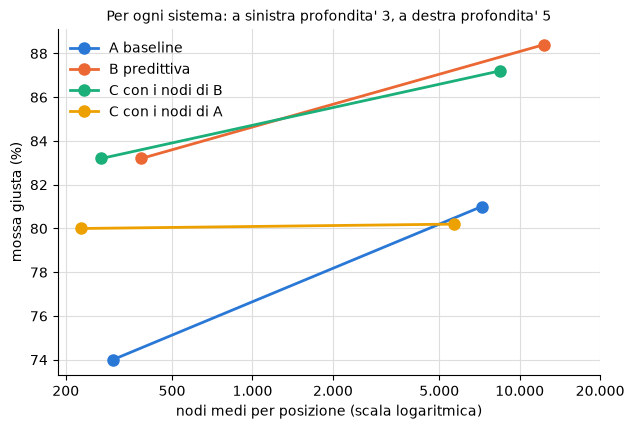

In [8]:
results3 = run_systems(positions, model, 3, T, RHO_MAX)

colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
fig, ax = plt.subplots(figsize=(7, 4.5))
all_nodes = []
for name, color in zip(SYSTEMS, colors):
    xs, ys = [], []
    for res in (results3, results):
        regrets, nodes, _ = zip(*res[name])
        xs.append(mean(nodes))
        ys.append(100 * mean(r == 0 for r in regrets))
    all_nodes += xs
    ax.plot(xs, ys, color=color, linewidth=2, marker="o", markersize=8, label=name.replace("  ", " "))
ax.set_title(f"Per ogni sistema: a sinistra profondita' 3, a destra profondita' {DEPTH}", fontsize=10)
ax.set_xscale("log")
ticks = [t for t in [100, 200, 500, 1000, 2000, 5000, 10000, 20000, 50000]
         if min(all_nodes) / 2 <= t <= max(all_nodes) * 2]
ax.set_xticks(ticks, [f"{t:,}".replace(",", ".") for t in ticks])
ax.minorticks_off()
ax.set_xlabel("nodi medi per posizione (scala logaritmica)")
ax.set_ylabel("mossa giusta (%)")
ax.grid(color="#ddd", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

In [9]:
compare_systems(results3)

sistema              mossa giusta   regret     nodi     rho
A  baseline                   74%     0.68      300   0.000
B  predittiva                 83%     0.44      383   0.000
C  con i nodi di B            83%     0.47      272   0.028
C  con i nodi di A            80%     0.57      228   0.026

rispetto a B          meglio  peggio
A  baseline               24      70
C  con i nodi di B         4       4
C  con i nodi di A         7      25


### Predizione o regolazione?

I due guadagni si leggono in punti diversi. Quello della **predizione** si vede
confrontando A e B a parità di nodi, nel grafico: B a profondità 3 contro A a profondità
3, che usa un numero di nodi simile, e contro A a profondità 5, che ne usa molti di più.
Quello della **regolazione** si vede confrontando C con B, che hanno la stessa
predizione: con i nodi di B, C sceglie quasi sempre come B spendendo meno nodi. Per
sapere se, a parità di budget, tagliare la frontiera migliori anche le decisioni, serve
la variante con il regolatore disattivato, più sotto.

## Quando conviene cercare una mossa che sembra brutta

Le mosse più pericolose per C sono quelle "brutte ma buone": le migliori per il maestro
che la predizione mette almeno `DELTA` pedine sotto la sua preferita. Il regolatore dà
loro poca probabilità e rischia di non cercarle mai. Quante sono, e quante sono anche
instabili, cioè riconoscibili da |r|?

In [10]:
print(f"mosse brutte ma buone: {len(hidden)}, di cui instabili {sum(hidden)}")

mosse brutte ma buone: 297, di cui instabili 82


Un caso concreto: la posizione in cui C, con i nodi di B, perde di più rispetto a B.
Per ogni mossa la predizione, la probabilità π iniziale, il valore finale in C (uguale
alla predizione se C non l'ha cercata) e il valore del maestro.

In [11]:
diffs = [c[0] - b[0] for b, c in zip(results["B  predittiva"], results["C  con i nodi di B"])]
k = int(np.argmax(diffs))
if diffs[k] <= 0:
    print("C con i nodi di B non fa mai peggio di B")
else:
    board, ref = positions[k]
    b_nodes = results["B  predittiva"][k][1]
    predicted = minimaxB(board, 1, model)[1]
    _, c_values, c_nodes, rho = minimaxC(board, DEPTH, model, b_nodes, T, RHO_MAX)
    pi = softmax(np.array(predicted) / T)
    side = "bianco" if board.turn == Color.WHITE else "nero"
    print(f"{board.fen}   muove il {side}")
    print(f"C usa {c_nodes} nodi (B {b_nodes}), rho finale {rho:.3f}\n")
    print(f"{'mossa':<10} {'predizione':>10} {'pi':>6} {'valore in C':>12} {'cercata':>8} {'maestro':>8}")
    for i, move in enumerate(board.legal_moves):
        searched = "si'" if c_values[i] != predicted[i] else ""
        print(f"{str(move):<10} {predicted[i]:>10.2f} {pi[i]:>6.3f} {c_values[i]:>12.2f} {searched:>8} {ref[i]:>8}")

    a_move = minimaxA(board, DEPTH)[0]
    b_move = minimaxB(board, DEPTH, model)[0]
    print(f"\nA sceglie {board.legal_moves[a_move]}, B sceglie {board.legal_moves[b_move]}")

[FEN "W:W15,19,20,K22,23,25,26,27,29,30:B8,10,11,12,16,17,21"]   muove il bianco
C usa 137 nodi (B 891), rho finale 0.000

mossa      predizione     pi  valore in C  cercata  maestro
27-24            4.40  0.008         4.40               5.0
23-18            2.47  0.000         2.47               4.0
22-18            3.99  0.003         3.99              24.0
15x6             6.34  0.954         8.65      si'      8.0
22x13            5.03  0.036         5.03               8.0

A sceglie 22-18, B sceglie 22-18


## Che cosa succede se…

Ogni cella cambia una sola cosa e rifà il confronto sulle prime `N_VARIANTS` posizioni.
Le varianti seguono l'ordine dell'elenco della consegna; le previsioni sono scritte
prima di eseguire la cella. Come riferimento, il sistema normale sulle stesse posizioni.

In [12]:
def variant(**changes):
    """Rifà il confronto sulle prime N_VARIANTS posizioni cambiando uno dei parametri."""
    params = {"model": model, "depth": DEPTH, "T": T, "rho_max": RHO_MAX} | changes
    compare_systems(run_systems(positions[:N_VARIANTS], **params))


print(f"Riferimento: sistema normale sulle prime {N_VARIANTS} posizioni\n")
compare_systems({name: rows[:N_VARIANTS] for name, rows in results.items()})

Riferimento: sistema normale sulle prime 150 posizioni

sistema              mossa giusta   regret     nodi     rho
A  baseline                   84%     0.17     7227   0.000
B  predittiva                 90%     0.10    11940   0.000
C  con i nodi di B            89%     0.19     7971   0.025
C  con i nodi di A            84%     0.25     5404   0.021

rispetto a B          meglio  peggio
A  baseline                7      16
C  con i nodi di B         1       2
C  con i nodi di A         3      12


**Il predittore è meno accurato** (rumore `NOISE` su tutti i pesi della rete).
*Previsione*: B e C peggiorano; C esclude mosse sbagliate più spesso.

In [13]:
noisy = copy.deepcopy(model)
rng = np.random.default_rng(0)
noisy.coefs_ = [w + rng.normal(0, NOISE, w.shape) for w in noisy.coefs_]
error, hit = accuracy(positions, lambda b: minimaxB(b, 1, noisy)[1])
print(f"predittore con rumore: errore medio {error:.2f} pedine, mossa migliore indovinata {hit:.0%}\n")
variant(model=noisy)

predittore con rumore: errore medio 1.42 pedine, mossa migliore indovinata 64%



sistema              mossa giusta   regret     nodi     rho
A  baseline                   84%     0.17     7227   0.000
B  predittiva                 85%     0.25    11152   0.000
C  con i nodi di B            85%     0.25     6937   0.025
C  con i nodi di A            81%     0.32     5072   0.024

rispetto a B          meglio  peggio
A  baseline               10      12
C  con i nodi di B         2       2
C  con i nodi di A         3       9


**La distribuzione π viene appiattita** (T = 3).
*Previsione*: servono più mosse per coprire il 95%, C ne esclude meno e diventa come B.

In [14]:
variant(T=3)

sistema              mossa giusta   regret     nodi     rho
A  baseline                   84%     0.17     7227   0.000
B  predittiva                 90%     0.10    11940   0.000
C  con i nodi di B            90%     0.10    11625   0.009
C  con i nodi di A            84%     0.17     7106   0.005

rispetto a B          meglio  peggio
A  baseline                7      16
C  con i nodi di B         0       0
C  con i nodi di A         2      11


**Il budget si riduce**: è il caso "C con i nodi di A" delle tabelle del confronto,
e la profondità 3 riduce il budget di tutti e tre i sistemi.

**Si toglie una fonte di incertezza**: nel nostro sistema l'unica incertezza che il
regolatore usa è quella di π. Toglierla vuol dire T molto piccola: π diventa quasi tutta
sulla favorita e C cerca solo quella, finché non delude. Non la eseguiamo; si prova con
`variant(T=0.05)`. *Previsione*: C usa pochissimi nodi e si avvicina alla sola
predizione.

**Il regolatore è disattivato ma la predizione resta** (ρ_max = 0: la frontiera
contiene sempre tutte le mosse, cercate nell'ordine di π).
*Previsione*: con i nodi di B, C diventa B. Con i nodi di A, C cerca tutte le mosse
finché ha nodi: confrontato con "C con i nodi di A" normale, isola il guadagno della
regolazione a parità di budget.

In [15]:
variant(rho_max=0)

sistema              mossa giusta   regret     nodi     rho
A  baseline                   84%     0.17     7227   0.000
B  predittiva                 90%     0.10    11940   0.000
C  con i nodi di B            90%     0.10    11806   0.000
C  con i nodi di A            84%     0.17     7114   0.000

rispetto a B          meglio  peggio
A  baseline                7      16
C  con i nodi di B         0       0
C  con i nodi di A         2      11


**La predizione resta ma il calcolo è distribuito in modo uniforme**: è esattamente il
sistema B, che dà a ogni mossa la stessa profondità.

**La massa residua deve restare più grande** (ρ_max = 0,3).
*Previsione*: C cerca meno mosse, usa meno nodi e ρ sale; la qualità scende un po'.

In [16]:
variant(rho_max=0.3)

sistema              mossa giusta   regret     nodi     rho
A  baseline                   84%     0.17     7227   0.000
B  predittiva                 90%     0.10    11940   0.000
C  con i nodi di B            87%     0.29     5416   0.183
C  con i nodi di A            82%     0.36     4286   0.182

rispetto a B          meglio  peggio
A  baseline                7      16
C  con i nodi di B         2       6
C  con i nodi di A         4      16


**Cambia la distribuzione di training**: richiede di rigenerare i dati e riallenare
la rete (`make_data.py`, `predictor.py`), quindi qui non la eseguiamo.

**C spende in profondità i nodi risparmiati** (C a profondità 6, con i nodi che B usa
a profondità 5). *Previsione*: l'idea è usare il risparmio sulle mosse improbabili per
cercare più a fondo le altre. Ma a 6 semimosse una mossa costa circa 5 volte tanto,
quindi C potrebbe riuscire a cercarne pochissime e lasciare le altre alla sola
predizione.

In [17]:
rows = []
for (board, ref), (b_regret, b_nodes, _) in zip(positions[:N_VARIANTS], results["B  predittiva"]):
    move, values, nodes, _ = minimaxC(board, 6, model, b_nodes, T, RHO_MAX)
    predicted = minimaxB(board, 1, model)[1]
    searched = int(sum(v != p for v, p in zip(values, predicted)))   # mosse cercate davvero a 6
    rows.append((max(ref) - ref[move], nodes, searched, b_regret))
regrets, nodes, searched, b_regrets = zip(*rows)

print(f"C a profondita' 6 con i nodi di B: mossa giusta {mean(r == 0 for r in regrets):.0%}, "
      f"regret {mean(regrets):.2f}, nodi {mean(nodes):.0f}")
print(f"mosse cercate a 6 in media: {mean(searched):.1f} su {mean(len(ref) for _, ref in positions[:N_VARIANTS]):.1f}")
print(f"rispetto a B: meglio in {sum(r < b for r, b in zip(regrets, b_regrets))}, "
      f"peggio in {sum(r > b for r, b in zip(regrets, b_regrets))}")

C a profondita' 6 con i nodi di B: mossa giusta 75%, regret 0.43, nodi 10628
mosse cercate a 6 in media: 1.0 su 7.4
rispetto a B: meglio in 4, peggio in 27
